<a href="https://colab.research.google.com/github/garvitSharma24112/machine-learning/blob/main/linearRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Ensure kagglehub is installed and up-to-date
!pip install kagglehub --upgrade --quiet

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
import pandas as pd
import os
import glob
import kagglehub

# Download the specified Kaggle dataset
try:
    path = kagglehub.dataset_download('himanshunakrani/student-study-hours')
    print("Path to dataset files:", path)

    # List contents of the downloaded path to identify the correct CSV file path
    print(f"Contents of directory {path}:")
    for item in os.listdir(path):
        print(f"- {item}")

    # Locate the CSV file within the downloaded path
    csv_files = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)

    df_kaggle = pd.DataFrame() # Initialize empty DataFrame
    if csv_files:
        csv_file = csv_files[0] # Assuming the first CSV found is the intended one
        print(f"Found CSV file at: {csv_file}")
        df_kaggle = pd.read_csv(csv_file)
        print("Columns in downloaded Kaggle dataset:", df_kaggle.columns.tolist())
        display(df_kaggle.head())
    else:
        print("No CSV file found in the downloaded Kaggle dataset.")

except Exception as e:
    print(f"Error downloading Kaggle dataset: {e}")
    df_kaggle = pd.DataFrame() # Ensure df_kaggle is defined even on error

Using Colab cache for faster access to the 'student-study-hours' dataset.
Path to dataset files: /kaggle/input/student-study-hours
Contents of directory /kaggle/input/student-study-hours:
- score.csv
- score_updated.csv
Found CSV file at: /kaggle/input/student-study-hours/score.csv
Columns in downloaded Kaggle dataset: ['Hours', 'Scores']


,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30



Performing Linear Regression for 'Study Hours vs Exam Scores'.

Model Equation: Scores = 2.48 + 9.78 * (Hours)


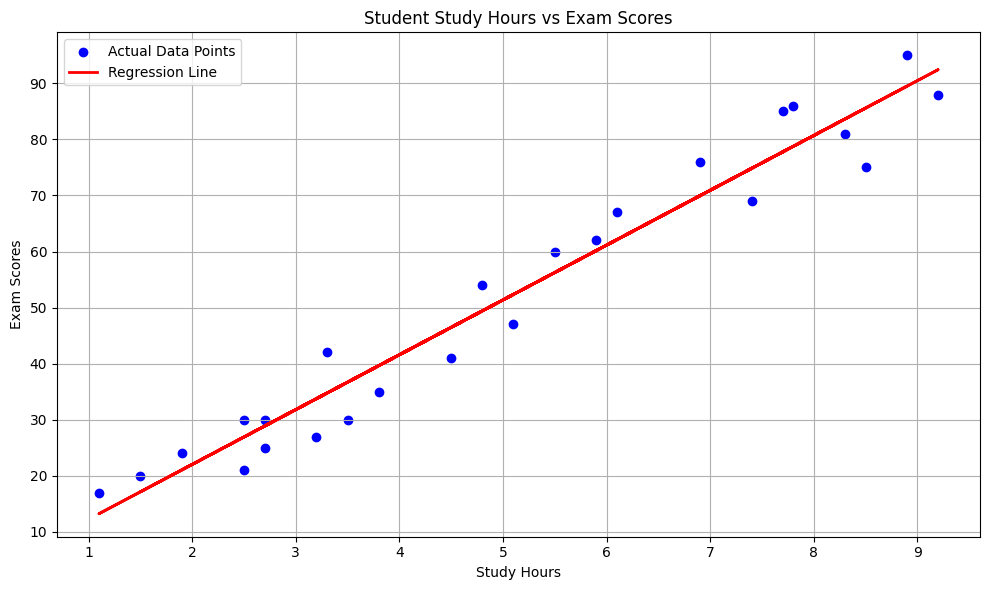

In [ ]:
if not df_kaggle.empty and 'Hours' in df_kaggle.columns and 'Scores' in df_kaggle.columns:
    print("\nPerforming Linear Regression for 'Study Hours vs Exam Scores'.")

    # Prepare the data
    X = df_kaggle['Hours'].values.reshape(-1, 1)  # Independent variable (Study Hours)
    y = df_kaggle['Scores'].values  # Dependent variable (Percentage Scores)

    # Initialize and train the linear regression model
    model = LinearRegression()
    model.fit(X, y)

    # Get the slope and intercept
    slope = model.coef_[0]
    intercept = model.intercept_

    print(f"\nModel Equation: Scores = {intercept:.2f} + {slope:.2f} * (Hours)")

    # Make predictions
    y_pred = model.predict(X)

    # Plotting the results
    plt.figure(figsize=(10, 6))
    plt.scatter(X, y, color='blue', label='Actual Data Points')
    plt.plot(X, y_pred, color='red', linewidth=2, label='Regression Line')

    plt.title('Student Study Hours vs Exam Scores')
    plt.xlabel('Study Hours')
    plt.ylabel('Exam Scores')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Kaggle dataset (df_kaggle) is empty or does not contain 'Hours' and 'Scores' columns. Skipping linear regression.")